coarse

In [6]:
import os
import numpy as np
import pandas as pd
from pyproj import Transformer

# ============================================================
# CONFIG
# ============================================================
INPUT_CSV  = r"E:\04.Pak_ival\Dataset\sumur_bandung\4nov25\1.360_raw\need_coarse\GS013978.csv"
OUTPUT_CSV = r"E:\04.Pak_ival\Dataset\sumur_bandung\4nov25\1.360_raw\need_coarse\GS013978_1.csv"

N_ENDPOINT = 10   # jumlah titik awal & akhir untuk averaging

# ============================================================
# LOAD CSV
# ============================================================

df = pd.read_csv(INPUT_CSV)
df = df.sort_values("t_rel_sec").reset_index(drop=True)

lat = df["lat"].values
lon = df["lon"].values
alt = df["alt"].values
n   = len(df)

# ============================================================
# WGS84 → ECEF (METRIC SPACE)
# ============================================================

to_ecef   = Transformer.from_crs("EPSG:4979", "EPSG:4978", always_xy=True)
from_ecef = Transformer.from_crs("EPSG:4978", "EPSG:4979", always_xy=True)

X, Y, Z = to_ecef.transform(lon, lat, alt)

# ============================================================
# COMPUTE STRAIGHT LINE (ECEF) — XYZ
# ============================================================

# Average first N points
A = np.array([
    X[:N_ENDPOINT].mean(),
    Y[:N_ENDPOINT].mean(),
    Z[:N_ENDPOINT].mean(),
])

# Average last N points
B = np.array([
    X[-N_ENDPOINT:].mean(),
    Y[-N_ENDPOINT:].mean(),
    Z[-N_ENDPOINT:].mean(),
])

# Linear interpolation parameter
alpha = np.linspace(0.0, 1.0, n)

X_s = A[0] + alpha * (B[0] - A[0])
Y_s = A[1] + alpha * (B[1] - A[1])
Z_s = A[2] + alpha * (B[2] - A[2])

# ============================================================
# ECEF → WGS84
# ============================================================

lon_s, lat_s, alt_s = from_ecef.transform(X_s, Y_s, Z_s)

# ============================================================
# SAVE OUTPUT
# ============================================================

df_out = df.copy()
df_out["lat"] = lat_s
df_out["lon"] = lon_s
df_out["alt"] = alt_s

os.makedirs(os.path.dirname(OUTPUT_CSV), exist_ok=True)
df_out.to_csv(OUTPUT_CSV, index=False)

print("DONE")
print("Trajectory forced to straight 3D line (XYZ, ECEF-based)")
print(f"Saved → {OUTPUT_CSV}")


DONE
Trajectory forced to straight 3D line (XYZ, ECEF-based)
Saved → E:\04.Pak_ival\Dataset\sumur_bandung\4nov25\1.360_raw\need_coarse\GS013978_1.csv


rapihin

In [1]:
import os
import glob
import pandas as pd
import numpy as np
from scipy.signal import savgol_filter

# ============================================================
# ======================= CONFIG =============================
# ============================================================

INPUT_CSV_DIR  = r"E:\04.Pak_ival\Dataset\sumur_bandung\4nov25\1.360_raw\output"
OUTPUT_CSV_DIR = r"E:\04.Pak_ival\Dataset\sumur_bandung\4nov25\1.360_raw\output_physical"

os.makedirs(OUTPUT_CSV_DIR, exist_ok=True)

# GPS ~3 FPS
ALT_WINDOW = 9          # smoothing window (odd)
XY_WINDOW  = 5          # smoothing window (odd)
POLY_ORDER = 2

SLOPE_MAX = 0.08        # 8% max slope (PHYSICAL CONSTRAINT)

# ============================================================
# ======================= HELPERS =============================
# ============================================================

def haversine(lat1, lon1, lat2, lon2):
    """Horizontal distance in meters"""
    R = 6371000.0
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi = np.radians(lat2 - lat1)
    dlambda = np.radians(lon2 - lon1)

    a = np.sin(dphi/2)**2 + np.cos(phi1)*np.cos(phi2)*np.sin(dlambda/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))


def apply_slope_constraint(df, slope_max):
    """Clamp vertical change based on horizontal distance"""
    z = df["alt"].values.copy()

    for i in range(1, len(df)):
        dxy = haversine(
            df.loc[i-1, "lat"], df.loc[i-1, "lon"],
            df.loc[i,   "lat"], df.loc[i,   "lon"]
        )

        dz_max = slope_max * dxy
        dz = z[i] - z[i-1]

        if abs(dz) > dz_max:
            z[i] = z[i-1] + np.sign(dz) * dz_max

    df["alt"] = z
    return df


def smooth_series(series, window, poly):
    if len(series) < window:
        return series
    return savgol_filter(series, window_length=window, polyorder=poly)

# ============================================================
# ======================= MAIN ================================
# ============================================================

csv_files = glob.glob(os.path.join(INPUT_CSV_DIR, "*.csv"))
print(f"Found {len(csv_files)} CSV files")

for csv_path in csv_files:
    name = os.path.basename(csv_path)
    out_path = os.path.join(OUTPUT_CSV_DIR, name)

    print(f"\nProcessing {name}")

    df = pd.read_csv(csv_path)
    df = df.sort_values("t_rel_sec").reset_index(drop=True)

    # ===================== STEP 1: PHYSICAL CONSTRAINT =========
    df = apply_slope_constraint(df, SLOPE_MAX)

    # ===================== STEP 2: SMOOTHING ===================
    df["alt"] = smooth_series(df["alt"].values, ALT_WINDOW, POLY_ORDER)
    df["lat"] = smooth_series(df["lat"].values, XY_WINDOW, POLY_ORDER)
    df["lon"] = smooth_series(df["lon"].values, XY_WINDOW, POLY_ORDER)

    # ===================== SAVE ================================
    df.to_csv(out_path, index=False)
    print(f"Saved → {out_path}")

print("\n=== PHYSICAL HEIGHT CORRECTION DONE ===")


Found 15 CSV files

Processing GS013969.csv
Saved → E:\04.Pak_ival\Dataset\sumur_bandung\4nov25\1.360_raw\output_physical\GS013969.csv

Processing GS013971.csv
Saved → E:\04.Pak_ival\Dataset\sumur_bandung\4nov25\1.360_raw\output_physical\GS013971.csv

Processing GS013972.csv
Saved → E:\04.Pak_ival\Dataset\sumur_bandung\4nov25\1.360_raw\output_physical\GS013972.csv

Processing GS013973.csv
Saved → E:\04.Pak_ival\Dataset\sumur_bandung\4nov25\1.360_raw\output_physical\GS013973.csv

Processing GS013974.csv
Saved → E:\04.Pak_ival\Dataset\sumur_bandung\4nov25\1.360_raw\output_physical\GS013974.csv

Processing GS013975.csv
Saved → E:\04.Pak_ival\Dataset\sumur_bandung\4nov25\1.360_raw\output_physical\GS013975.csv

Processing GS013976.csv
Saved → E:\04.Pak_ival\Dataset\sumur_bandung\4nov25\1.360_raw\output_physical\GS013976.csv

Processing GS013977.csv
Saved → E:\04.Pak_ival\Dataset\sumur_bandung\4nov25\1.360_raw\output_physical\GS013977.csv

Processing GS013978.csv
Saved → E:\04.Pak_ival\Datas

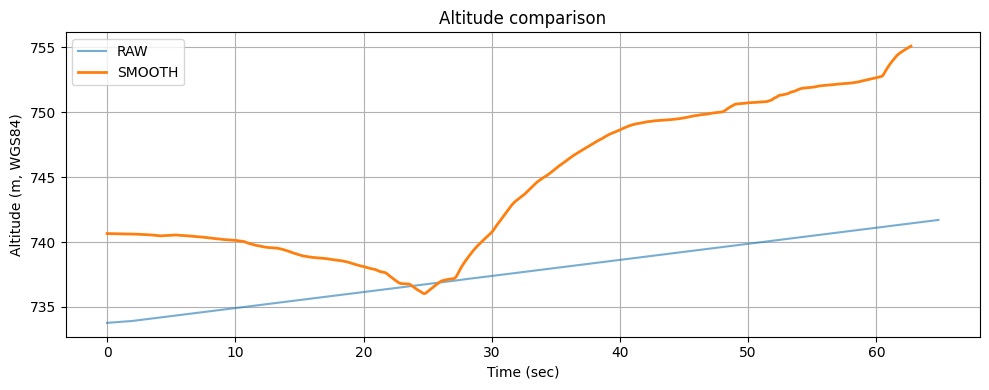

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

raw_csv    = r"E:\04.Pak_ival\Dataset\sumur_bandung\4nov25\1.360_raw\need_coarse\GS013978_1.csv"
smooth_csv = r"E:\04.Pak_ival\Dataset\sumur_bandung\4nov25\1.360_raw\output_physical\GS013980.csv"

raw = pd.read_csv(raw_csv)
smo = pd.read_csv(smooth_csv)

plt.figure(figsize=(10,4))
plt.plot(raw["t_rel_sec"], raw["alt"], label="RAW", alpha=0.6)
plt.plot(smo["t_rel_sec"], smo["alt"], label="SMOOTH", linewidth=2)

plt.xlabel("Time (sec)")
plt.ylabel("Altitude (m, WGS84)")
plt.title("Altitude comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
